### Step 1: Overview of Problem Statement

# Automobile Price Prediction Using Machine Learning
**Domain:** Automotive Industry & Market Analytics 

---

## 1. Overview of Problem Statement
A Chinese automobile company aspires to enter the US market by establishing a local manufacturing facility and producing cars domestically to compete directly with established US and European automakers. Entering a mature and competitive automotive market requires deep insight into the pricing dynamics and consumer valuation of vehicle specifications in the American market, which diverge substantially from Chinese consumer preferences and regulatory environments.

To determine an optimal design and pricing strategy, the company contracted an automobile consulting firm to analyze historical market surveys and technical attributes across vehicles sold in the United States. The primary business challenges to address are:
1. Which independent variables (e.g., horsepower, engine size, curb weight, dimensions, fuel system) are statistically significant in predicting vehicle pricing?
2. How well do these variables describe and explain the variance in car prices?

By building a robust, interpretable machine learning regression model, management can quantitatively understand the pricing sensitivity of key specifications. This enables engineering and product teams to manipulate vehicle design parameters, optimize manufacturing bills of materials (BOM), and establish competitive price points across targeted vehicle tiers.

## 2. Objective
The primary objective of this project is to build, evaluate, and fine-tune multiple supervised regression machine learning models to accurately predict continuous automobile prices (`price`) and quantify the pricing dynamics of the US market.

Specific technical and business objectives include:
1. Identifying and isolating the key technical and design drivers of vehicle prices through rigorous Exploratory Data Analysis (EDA) and inferential statistical testing.
2. Implementing a comprehensive data preprocessing pipeline, addressing missing values, eliminating outliers, resolving distribution skewness, and generating domain-specific engineered features.
3. Performing feature selection using statistical significance, correlation analysis, and tree-based importance metrics to distinguish high-impact engineering attributes from redundant noise.
4. Training and benchmarking at least five distinct regression algorithms (e.g., Linear Regression, Ridge/Lasso Regularization, Support Vector Regressor, Random Forest Regressor, and Gradient Boosting Regressor) using standard evaluation metrics ($R^2$, Adjusted $R^2$, MAE, RMSE).
5. Assembling an optimized, end-to-end `scikit-learn` pipeline and serializing the model artifact for inference on unseen automotive inventory records.

## 3. Data Description
- **Dataset Source:** US Market Automobile Pricing & Technical Survey Dataset (Geely Auto Consulting Data / Kaggle CarPrice Dataset)
- **Total Records (Rows):** 205
- **Total Attributes (Columns):** 26 (1 Identifier + 24 Feature columns + 1 Target column)

### Feature Breakdown:
- **Identifiers & Metadata:**
  - `car_ID`: Unique integer identifier for each automobile entry.
  - `symboling`: Insurance risk rating assigned to the vehicle (-3: very safe to +3: high risk).
  - `CarName`: Manufacturer and model nomenclature string (e.g., "alfa-romero giulia", "audi 100 ls").

- **Categorical & Structural Specifications:**
  - `fueltype`: Engine fuel category (`gas`, `diesel`).
  - `aspiration`: Induction method (`std` for naturally aspirated, `turbo` for turbocharged).
  - `doornumber`: Count of passenger doors (`two`, `four`).
  - `carbody`: Vehicle chassis configuration (`sedan`, `hatchback`, `wagon`, `hardtop`, `convertible`).
  - `drivewheel`: Drivetrain axle configuration (`fwd`, `rwd`, `4wd`).
  - `enginelocation`: Spatial chassis placement of engine (`front`, `rear`).
  - `enginetype`: Engine block layout (`ohc`, `ohcv`, `ohcf`, `l`, `dohc`, `rotor`, `dohcv`).
  - `cylindernumber`: Integer string count of combustion cylinders (`four`, `six`, `five`, `eight`, `two`, `three`, `twelve`).
  - `fuelsystem`: Induction delivery mechanism (`mpfi`, `2bbl`, `idi`, `1bbl`, `spdi`, `4bbl`, `mfi`, `spfi`).

- **Continuous Dimensional & Physical Metrics:**
  - `wheelbase`: Longitudinal distance between centers of front and rear wheels (inches).
  - `carlength`: Overall vehicle exterior length (inches).
  - `carwidth`: Overall vehicle exterior width (inches).
  - `carheight`: Overall vehicle exterior height (inches).
  - `curbweight`: Total vehicle unladen weight with standard fluids (lbs).

- **Powertrain & Performance Characteristics:**
  - `enginesize`: Total cylinder displacement volume (cubic inches).
  - `boreratio`: Combustion cylinder diameter ratio (inches).
  - `stroke`: Piston linear travel distance within cylinder (inches).
  - `compressionratio`: Combustion volume ratio between bottom and top dead centers.
  - `horsepower`: Brake power metric generated by the engine (hp).
  - `peakrpm`: Engine rotational speed delivering maximum horsepower output (RPM).
  - `citympg`: Estimated fuel economy under urban transit conditions (miles per gallon).
  - `highwaympg`: Estimated fuel economy under steady-state highway transit (miles per gallon).

- **Target Variable:**
  - `price`: Final retail vehicle price in US Dollars (Continuous numerical target for regression).

## 4. Data Collection & Ingestion
In this step, we load the raw automobile dataset into a Pandas DataFrame and perform structural exploration and foundational data wrangling using NumPy and Pandas (slicing, boolean indexing, loc/iloc operations, groupby aggregations, and merging).

In [1]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Load the automobile dataset
dataset_path = 'CarPrice_Assignment.csv'
df = pd.read_csv(dataset_path)

print(f"Dataset successfully loaded.")
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")

Dataset successfully loaded.
Total Rows: 205
Total Columns: 26


In [2]:
# Display the first 5 records
print("--- FIRST 5 ROWS ---")
display(df.head())

# Display the last 5 records
print("\n--- LAST 5 ROWS ---")
display(df.tail())

# Check data types, non-null counts, and memory footprint
print("\n--- DATASET INFO ---")
df.info()

# Summary statistics for numerical attributes
print("\n--- DESCRIPTIVE SUMMARY STATISTICS ---")
display(df.describe().T)


--- FIRST 5 ROWS ---


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0



--- LAST 5 ROWS ---


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
200,201,-1,volvo 145e (sw),gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0
201,202,-1,volvo 144ea,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0
204,205,-1,volvo 264gl,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625.0



--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 

,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17


In [3]:
# List all column names and their data types
print("Columns in Dataset:")
print(df.columns.tolist())

# Check unique values count per feature
print("\n--- UNIQUE VALUE COUNTS PER COLUMN ---")
print(df.nunique())

# Inspect categorical distributions using value_counts
categorical_cols = [
    'fueltype', 'aspiration', 'doornumber', 'carbody', 
    'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem'
]
for col in categorical_cols:
    print(f"\nDistribution of '{col}':")
    print(df[col].value_counts())

Columns in Dataset:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

--- UNIQUE VALUE COUNTS PER COLUMN ---
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg         

In [4]:
# 1. Indexing with .iloc (integer position-based selection)
print("--- ILOC SLICE (First 5 rows, first 5 columns) ---")
display(df.iloc[:5, :5])

# 2. Boolean indexing combined with .loc (label-based conditional selection: high horsepower > 150)
print("\n--- LOC SLICE (High Performance Cars: Horsepower > 150) ---")
high_hp_cars = df.loc[df['horsepower'] > 150, ['CarName', 'carbody', 'horsepower', 'enginesize', 'price']]
display(high_hp_cars.head())

# 3. GroupBy Aggregation: Mean price, average horsepower, and count per carbody and drivewheel
print("\n--- GROUPBY AGGREGATION: Carbody & Drivewheel ---")
body_drive_summary = df.groupby(['carbody', 'drivewheel']).agg(
    Avg_Price=('price', 'mean'),
    Avg_Horsepower=('horsepower', 'mean'),
    Vehicle_Count=('car_ID', 'count')
).reset_index()
display(body_drive_summary)

# 4. Merge operation: Joining aggregate benchmarks back onto a subset
print("\n--- MERGE OPERATION ---")
merged_sample = pd.merge(
    df[['car_ID', 'CarName', 'carbody', 'drivewheel', 'price']].head(5),
    body_drive_summary[['carbody', 'drivewheel', 'Avg_Price']],
    on=['carbody', 'drivewheel'],
    how='left'
)
display(merged_sample)

--- ILOC SLICE (First 5 rows, first 5 columns) ---


,car_ID,symboling,CarName,fueltype,aspiration
0,1,3,alfa-romero giulia,gas,std
1,2,3,alfa-romero stelvio,gas,std
2,3,1,alfa-romero Quadrifoglio,gas,std
3,4,2,audi 100 ls,gas,std
4,5,2,audi 100ls,gas,std



--- LOC SLICE (High Performance Cars: Horsepower > 150) ---


,CarName,carbody,horsepower,enginesize,price
2,alfa-romero Quadrifoglio,hatchback,154,152,16500.000
9,audi 5000s (diesel),hatchback,160,131,17859.167
15,bmw x4,sedan,182,209,30760.000
16,bmw x5,sedan,182,209,41315.000
17,bmw x3,sedan,182,209,36880.000



--- GROUPBY AGGREGATION: Carbody & Drivewheel ---


,carbody,drivewheel,Avg_Price,Avg_Horsepower,Vehicle_Count
0,convertible,fwd,11595.000000,90.000000,1
1,convertible,rwd,23949.600000,140.000000,5
2,hardtop,fwd,8249.000000,69.000000,1
3,hardtop,rwd,24202.714286,152.714286,7
4,hatchback,4wd,12731.083500,116.500000,2
5,hatchback,fwd,8396.387755,84.897959,49
6,hatchback,rwd,15235.815789,141.526316,19
7,sedan,4wd,12647.333333,102.666667,3
8,sedan,fwd,9780.385965,86.631579,57
9,sedan,rwd,21711.833333,129.222222,36



--- MERGE OPERATION ---


,car_ID,CarName,carbody,drivewheel,price,Avg_Price
0,1,alfa-romero giulia,convertible,rwd,13495.0,23949.600000
1,2,alfa-romero stelvio,convertible,rwd,16500.0,23949.600000
2,3,alfa-romero Quadrifoglio,hatchback,rwd,16500.0,15235.815789
3,4,audi 100 ls,sedan,fwd,13950.0,9780.385965
4,5,audi 100ls,sedan,4wd,17450.0,12647.333333


## 5. Data Preprocessing — Data Cleaning
Data cleaning ensures dataset integrity prior to exploratory data analysis and modeling. In this step, we:
1. Audit and treat missing values (demonstrating `SimpleImputer` from scikit-learn).
2. Check for and eliminate duplicate entries.
3. Detect statistical outliers using IQR and Z-score methods, applying Winsorization/capping.
4. Measure skewness across continuous features and apply transformations (`log1p` and `sqrt`) to normalize right-skewed distributions.

In [5]:
from sklearn.impute import SimpleImputer

# 1. Audit missing values across all features
print("--- MISSING VALUES AUDIT ---")
null_counts = df.isnull().sum()
print(null_counts)

# 2. Roadmap Requirement Demonstration: Handling Missing Values with SimpleImputer
# Creating a demonstration subset to showcase mean and median imputation
print("\n--- DEMONSTRATION OF SIMPLEIMPUTER (Mean & Median) ---")
demo_df = df[['enginesize', 'horsepower']].copy()

# Introduce 5% synthetic null values for demonstration purposes
np.random.seed(42)
mask = np.random.rand(*demo_df.shape) < 0.05
demo_df[mask] = np.nan
print("Synthetic Missing Values Introduced for Demonstration:")
print(demo_df.isnull().sum())

# Apply Mean Imputation using SimpleImputer
mean_imputer = SimpleImputer(strategy='mean')
demo_imputed_mean = mean_imputer.fit_transform(demo_df)
print("Null count after Mean SimpleImputer:", np.isnan(demo_imputed_mean).sum())

# Apply Median Imputation using SimpleImputer
median_imputer = SimpleImputer(strategy='median')
demo_imputed_median = median_imputer.fit_transform(demo_df)
print("Null count after Median SimpleImputer:", np.isnan(demo_imputed_median).sum())

--- MISSING VALUES AUDIT ---
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

--- DEMONSTRATION OF SIMPLEIMPUTER (Mean & Median) ---
Synthetic Missing Values Introduced for Demonstration:
enginesize    15
horsepower    12
dtype: int64
Null count after Mean SimpleImputer: 0
Null count after Median SimpleImputer: 0


In [6]:
# Check for exact duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Total Duplicate Rows Found: {duplicate_count}")

if duplicate_count > 0:
    df.drop_duplicates(inplace=True)
    print(f"Duplicates removed. Remaining rows: {df.shape[0]:,}")
else:
    print("Dataset contains zero duplicate rows. No row pruning required.")

Total Duplicate Rows Found: 0
Dataset contains zero duplicate rows. No row pruning required.


In [7]:
from scipy import stats

outlier_cols = ['wheelbase', 'carlength', 'carwidth', 'curbweight', 'enginesize', 'horsepower', 'price']
print("--- OUTLIER DETECTION & TREATMENT (IQR METHOD) ---")

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"\nFeature: '{col}'")
    print(f"  Q1 (25th): {Q1:.2f} | Q3 (75th): {Q3:.2f} | IQR: {IQR:.2f}")
    print(f"  Lower Bound: {lower_bound:.2f} | Upper Bound: {upper_bound:.2f}")
    print(f"  Outliers Detected: {len(outliers):,} ({len(outliers)/len(df)*100:.2f}%)")

# Z-score outlier inspection (|Z| > 3)
print("\n--- Z-SCORE OUTLIER INSPECTION (|Z| > 3) ---")
z_scores = np.abs(stats.zscore(df[outlier_cols]))
outliers_z = (z_scores > 3).sum(axis=0)
for idx, col in enumerate(outlier_cols):
    print(f"  {col}: {outliers_z[idx]:,} records with |Z| > 3")

# Treatment: Outlier Capping (Winsorization) using IQR bounds to retain all records
df_clean = df.copy()
for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = max(0, Q1 - 1.5 * IQR)
    upper_bound = Q3 + 1.5 * IQR
    
    df_clean[col] = np.clip(df_clean[col], lower_bound, upper_bound)

print("\nOutlier capping successfully applied using IQR bounds.")

--- OUTLIER DETECTION & TREATMENT (IQR METHOD) ---

Feature: 'wheelbase'
  Q1 (25th): 94.50 | Q3 (75th): 102.40 | IQR: 7.90
  Lower Bound: 82.65 | Upper Bound: 114.25
  Outliers Detected: 3 (1.46%)

Feature: 'carlength'
  Q1 (25th): 166.30 | Q3 (75th): 183.10 | IQR: 16.80
  Lower Bound: 141.10 | Upper Bound: 208.30
  Outliers Detected: 1 (0.49%)

Feature: 'carwidth'
  Q1 (25th): 64.10 | Q3 (75th): 66.90 | IQR: 2.80
  Lower Bound: 59.90 | Upper Bound: 71.10
  Outliers Detected: 8 (3.90%)

Feature: 'curbweight'
  Q1 (25th): 2145.00 | Q3 (75th): 2935.00 | IQR: 790.00
  Lower Bound: 960.00 | Upper Bound: 4120.00
  Outliers Detected: 0 (0.00%)

Feature: 'enginesize'
  Q1 (25th): 97.00 | Q3 (75th): 141.00 | IQR: 44.00
  Lower Bound: 31.00 | Upper Bound: 207.00
  Outliers Detected: 10 (4.88%)

Feature: 'horsepower'
  Q1 (25th): 70.00 | Q3 (75th): 116.00 | IQR: 46.00
  Lower Bound: 1.00 | Upper Bound: 185.00
  Outliers Detected: 6 (2.93%)

Feature: 'price'
  Q1 (25th): 7788.00 | Q3 (75th): 165

In [8]:
# Continuous numerical columns to inspect for skewness
continuous_cols = [
    'wheelbase', 'carlength', 'carwidth', 'carheight', 
    'curbweight', 'enginesize', 'boreratio', 'stroke', 
    'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price'
]

print("--- SKEWNESS EVALUATION BEFORE TRANSFORMATION ---")
initial_skew = df_clean[continuous_cols].skew()
print(initial_skew)

# Applying transformations on skewed features (enginesize and compressionratio)
print("\n--- APPLYING SKEWNESS TRANSFORMATIONS ---")

# 1. Log transformation using np.log1p
df_clean['enginesize_log'] = np.log1p(df_clean['enginesize'])
print(f"Engine Size Skewness (Original): {df_clean['enginesize'].skew():.4f}")
print(f"Engine Size Skewness (After log1p): {df_clean['enginesize_log'].skew():.4f}")

# 2. Square-root transformation on compression ratio
df_clean['compressionratio_sqrt'] = np.sqrt(df_clean['compressionratio'])
print(f"\nCompression Ratio Skewness (Original): {df_clean['compressionratio'].skew():.4f}")
print(f"Compression Ratio Skewness (After sqrt): {df_clean['compressionratio_sqrt'].sqrt() if hasattr(df_clean['compressionratio_sqrt'], 'sqrt') else df_clean['compressionratio_sqrt'].skew():.4f}")

--- SKEWNESS EVALUATION BEFORE TRANSFORMATION ---
wheelbase           0.924916
carlength           0.155954
carwidth            0.776278
carheight           0.063123
curbweight          0.681398
enginesize          0.908453
boreratio           0.020156
stroke             -0.689705
compressionratio    2.610862
horsepower          0.814957
peakrpm             0.075159
citympg             0.663704
highwaympg          0.539997
price               1.222031
dtype: float64

--- APPLYING SKEWNESS TRANSFORMATIONS ---
Engine Size Skewness (Original): 0.9085
Engine Size Skewness (After log1p): 0.4060

Compression Ratio Skewness (Original): 2.6109
Compression Ratio Skewness (After sqrt): 2.5058


## 6. Exploratory Data Analysis (EDA) & Statistical Testing
In this phase, we conduct thorough descriptive, visual, and inferential statistical analyses to understand automotive pricing patterns and variable dependencies:
1. **Descriptive Statistics:** Measures of Central Tendency (Mean, Median, Mode), Dispersion (Std Dev, Variance, Range), Skewness, and Kurtosis.
2. **Roadmap Visualizations:** Histogram, Kernel Density Estimation (KDE), Boxplot, Count Plot, Bar Plot, Pie Diagram, Line Plot, Correlation Heatmap, and Pair Plot.
3. **Inferential Hypothesis Testing:**
   - Two-Sample Independent t-Test (Impact of Aspiration Type on Vehicle Price).
   - One-Way ANOVA Test (Price Variance across Carbody Configurations).
   - Chi-Square Test of Independence (Association between Drivewheel and Carbody).

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure visualization styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

# Key numerical columns for statistical evaluation
numerical_features = [
    'wheelbase', 'carlength', 'carwidth', 'curbweight', 
    'enginesize', 'horsepower', 'citympg', 'highwaympg', 'price'
]

print("--- DESCRIPTIVE STATISTICS: CENTRAL TENDENCY & DISPERSION ---")
stats_summary = pd.DataFrame({
    'Mean': df_clean[numerical_features].mean(),
    'Median': df_clean[numerical_features].median(),
    'Mode': df_clean[numerical_features].mode().iloc[0],
    'Std Dev': df_clean[numerical_features].std(),
    'Variance': df_clean[numerical_features].var(),
    'Range': df_clean[numerical_features].max() - df_clean[numerical_features].min(),
    'Skewness': df_clean[numerical_features].skew(),
    'Kurtosis': df_clean[numerical_features].kurtosis()
})
display(stats_summary)

--- DESCRIPTIVE STATISTICS: CENTRAL TENDENCY & DISPERSION ---


,Mean,Median,Mode,Std Dev,Variance,Range,Skewness,Kurtosis
wheelbase,98.710976,97.0,94.5,5.882586,3.460482e+01,27.65,0.924916,0.480781
carlength,174.049268,173.2,157.3,12.337289,1.522087e+02,67.00,0.155954,-0.082895
carwidth,65.884390,65.5,63.8,2.083114,4.339363e+00,10.80,0.776278,0.309519
curbweight,2555.565854,2414.0,2385.0,520.680204,2.711079e+05,2578.00,0.681398,-0.042854
enginesize,124.570732,120.0,92.0,33.974343,1.154256e+03,146.00,0.908453,0.081191
horsepower,102.843902,95.0,68.0,35.578896,1.265858e+03,137.00,0.814957,-0.267304
citympg,25.219512,24.0,31.0,6.542142,4.279962e+01,36.00,0.663704,0.578648
highwaympg,30.751220,30.0,25.0,6.886443,4.742310e+01,38.00,0.539997,0.440070
price,12831.310571,10295.0,29575.5,6716.631714,4.511314e+07,24457.50,1.222031,0.690127


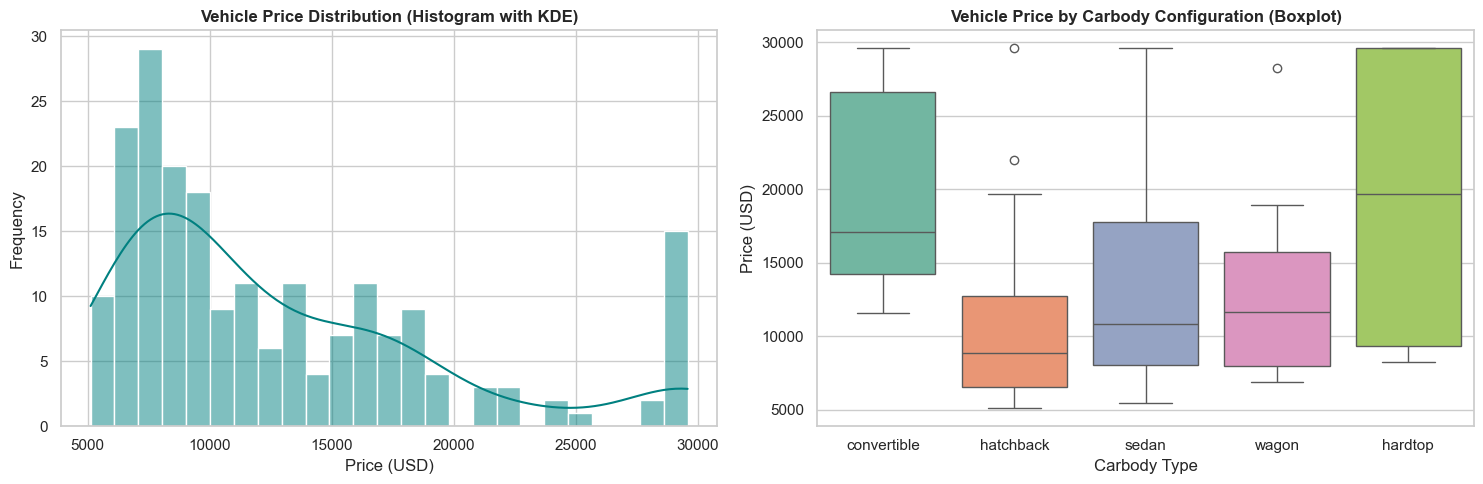

In [10]:
# 1. Histogram & Kernel Density Estimation (KDE) for Target Feature 'price'
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df_clean['price'], kde=True, color='teal', ax=axes[0], bins=25)
axes[0].set_title('Vehicle Price Distribution (Histogram with KDE)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Price (USD)')
axes[0].set_ylabel('Frequency')

# 2. Boxplot: Outliers and quartile distributions across Carbody types
sns.boxplot(x='carbody', y='price', data=df_clean, palette='Set2', ax=axes[1])
axes[1].set_title('Vehicle Price by Carbody Configuration (Boxplot)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Carbody Type')
axes[1].set_ylabel('Price (USD)')

plt.tight_layout()
plt.show()

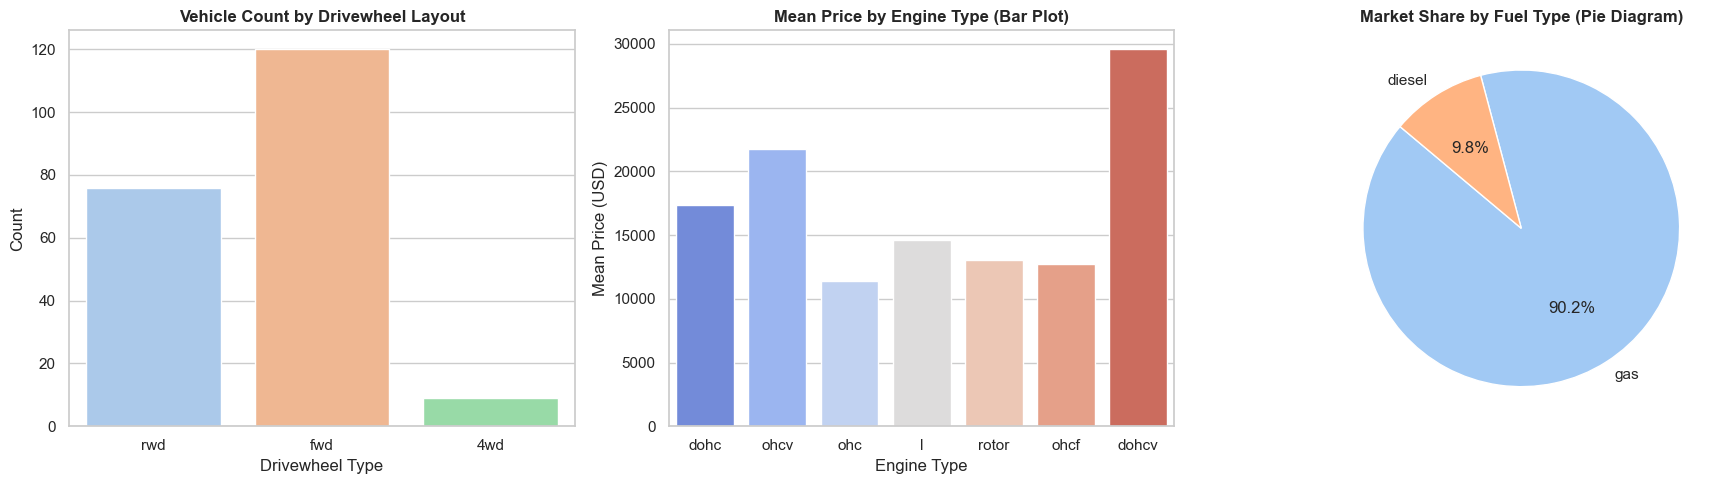

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 3. Count Plot: Transaction volume by Drivewheel layout
sns.countplot(x='drivewheel', data=df_clean, palette='pastel', ax=axes[0])
axes[0].set_title('Vehicle Count by Drivewheel Layout', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Drivewheel Type')
axes[0].set_ylabel('Count')

# 4. Bar Plot: Average Price across Engine Types
sns.barplot(x='enginetype', y='price', data=df_clean, palette='coolwarm', ci=None, ax=axes[1])
axes[1].set_title('Mean Price by Engine Type (Bar Plot)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Engine Type')
axes[1].set_ylabel('Mean Price (USD)')

# 5. Pie Diagram: Share of Fuel Types in Dataset
fuel_counts = df_clean['fueltype'].value_counts()
axes[2].pie(fuel_counts, labels=fuel_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
axes[2].set_title('Market Share by Fuel Type (Pie Diagram)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [12]:
print("--- INFERENTIAL HYPOTHESIS TESTING ---")

# 1. Two-Sample Independent t-Test: Aspiration (std vs. turbo) on Price
std_prices = df_clean[df_clean['aspiration'] == 'std']['price']
turbo_prices = df_clean[df_clean['aspiration'] == 'turbo']['price']
t_stat, p_val_t = stats.ttest_ind(std_prices, turbo_prices, equal_var=False)

print(f"\n1. Two-Sample t-Test (Aspiration vs. Price):")
print(f"   t-statistic: {t_stat:.4f}, p-value: {p_val_t:.4e}")
if p_val_t < 0.05:
    print("   Result: Reject Null Hypothesis (Aspiration type significantly affects price).")
else:
    print("   Result: Fail to reject Null Hypothesis.")

# 2. One-Way ANOVA Test: Carbody types (sedan, hatchback, etc.) on Price
carbody_groups = [group['price'].values for _, group in df_clean.groupby('carbody')]
f_stat, p_val_f = stats.f_oneway(*carbody_groups)

print(f"\n2. One-Way ANOVA Test (Carbody Configuration vs. Price):")
print(f"   F-statistic: {f_stat:.4f}, p-value: {p_val_f:.4e}")
if p_val_f < 0.05:
    print("   Result: Reject Null Hypothesis (Significant price variance across carbody styles).")
else:
    print("   Result: Fail to reject Null Hypothesis.")

# 3. Chi-Square Test of Independence: Carbody vs. Drivewheel
contingency_table = pd.crosstab(df_clean['carbody'], df_clean['drivewheel'])
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)

print(f"\n3. Chi-Square Test of Independence (Carbody vs. Drivewheel):")
print(f"   Chi2-statistic: {chi2_stat:.4f}, p-value: {p_val_chi2:.4e}, Degrees of Freedom: {dof}")
if p_val_chi2 < 0.05:
    print("   Result: Reject Null Hypothesis (Significant association between carbody and drivewheel).")
else:
    print("   Result: Fail to reject Null Hypothesis.")

--- INFERENTIAL HYPOTHESIS TESTING ---

1. Two-Sample t-Test (Aspiration vs. Price):
   t-statistic: -3.7612, p-value: 3.9819e-04
   Result: Reject Null Hypothesis (Aspiration type significantly affects price).

2. One-Way ANOVA Test (Carbody Configuration vs. Price):
   F-statistic: 7.1068, p-value: 2.2741e-05
   Result: Reject Null Hypothesis (Significant price variance across carbody styles).

3. Chi-Square Test of Independence (Carbody vs. Drivewheel):
   Chi2-statistic: 26.5904, p-value: 8.3179e-04, Degrees of Freedom: 8
   Result: Reject Null Hypothesis (Significant association between carbody and drivewheel).


## 7. Feature Engineering
Feature engineering extracts informative domain-specific signals and translates raw text or categorical columns into machine-interpretable numerical representations[cite: 1]. In this phase, we:
1. Extract the vehicle brand (`company_name`) from the composite `CarName` column and standardize misspelled manufacturer strings.
2. Segment brands into economic valuation tiers (`Budget`, `Mid-Range`, `Luxury`) to capture brand equity premiums.
3. Engineer technical performance ratios:
   - `power_to_weight`: Ratio of horsepower to vehicle curb weight ($hp / lbs$).
   - `car_volume`: Geometric exterior package volume ($carlength \times carwidth \times carheight$).
   - `overall_mpg`: Harmonic mean approximation of fuel efficiency across city and highway profiles.
4. Perform binary mapping, Label Encoding for ordinal/structural features, and One-Hot Encoding for multi-class nominal features[cite: 1].

In [13]:
# Create a copy for feature engineering
df_fe = df_clean.copy()

# 1. Extract company name from the composite CarName field
df_fe['company_name'] = df_fe['CarName'].apply(lambda x: x.split(' ')[0].lower())

# Standardize common typos in manufacturer names
brand_corrections = {
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen'
}
df_fe['company_name'] = df_fe['company_name'].replace(brand_corrections)

print("Unique Extracted Automotive Brands:")
print(df_fe['company_name'].unique())

# 2. Segment brands into Brand Equity Tiers based on market pricing brackets
budget_brands = ['chevrolet', 'dodge', 'honda', 'isuzu', 'mitsubishi', 'nissan', 'plymouth', 'renault', 'subaru', 'toyota']
mid_brands = ['alfa-romero', 'mazda', 'peugeot', 'saab', 'volkswagen', 'volvo']
luxury_brands = ['audi', 'bmw', 'buick', 'jaguar', 'porsche', 'mercury']

def assign_brand_tier(company):
    if company in luxury_brands:
        return 'Luxury'
    elif company in mid_brands:
        return 'Mid-Range'
    else:
        return 'Budget'

df_fe['brand_tier'] = df_fe['company_name'].apply(assign_brand_tier)
print("\nDistribution of Brand Tiers:")
print(df_fe['brand_tier'].value_counts())

# 3. Engineer Powertrain & Geometric Metrics
df_fe['power_to_weight'] = df_fe['horsepower'] / df_fe['curbweight']
df_fe['car_volume'] = df_fe['carlength'] * df_fe['carwidth'] * df_fe['carheight']
df_fe['overall_mpg'] = (df_fe['citympg'] + df_fe['highwaympg']) / 2.0

display(df_fe[['company_name', 'brand_tier', 'power_to_weight', 'car_volume', 'overall_mpg', 'price']].head())

Unique Extracted Automotive Brands:
['alfa-romero' 'audi' 'bmw' 'chevrolet' 'dodge' 'honda' 'isuzu' 'jaguar'
 'mazda' 'buick' 'mercury' 'mitsubishi' 'nissan' 'peugeot' 'plymouth'
 'porsche' 'renault' 'saab' 'subaru' 'toyota' 'volkswagen' 'volvo']

Distribution of Brand Tiers:
brand_tier
Budget       113
Mid-Range     60
Luxury        32
Name: count, dtype: int64


,company_name,brand_tier,power_to_weight,car_volume,overall_mpg,price
0,alfa-romero,Mid-Range,0.043564,528019.904,24.0,13495.0
1,alfa-romero,Mid-Range,0.043564,528019.904,24.0,16500.0
2,alfa-romero,Mid-Range,0.054552,587592.640,22.5,16500.0
3,audi,Luxury,0.043646,634816.956,27.0,13950.0
4,audi,Luxury,0.040722,636734.832,20.0,17450.0


In [14]:
from sklearn.preprocessing import LabelEncoder

# 1. Binary & Ordinal Feature Mapping
# Map string numbers to numerical counts
doors_map = {'two': 2, 'four': 4}
cylinders_map = {'two': 2, 'three': 3, 'four': 4, 'five': 5, 'six': 6, 'eight': 8, 'twelve': 12}

df_fe['doornumber'] = df_fe['doornumber'].map(doors_map)
df_fe['cylindernumber'] = df_fe['cylindernumber'].map(cylinders_map)

# Binary flag mappings
df_fe['fueltype'] = df_fe['fueltype'].map({'gas': 1, 'diesel': 0})
df_fe['aspiration'] = df_fe['aspiration'].map({'std': 0, 'turbo': 1})
df_fe['enginelocation'] = df_fe['enginelocation'].map({'front': 0, 'rear': 1})

# Ordinal Brand Tier Label Encoding
tier_encoder = LabelEncoder()
df_fe['brand_tier_encoded'] = tier_encoder.fit_transform(df_fe['brand_tier'])

# 2. One-Hot Encoding for Multi-Class Nominal Features
nominal_cols = ['carbody', 'drivewheel', 'enginetype', 'fuelsystem']
df_encoded = pd.get_dummies(df_fe, columns=nominal_cols, drop_first=True)

# Prune unneeded identifier and raw text columns
drop_cols = ['car_ID', 'CarName', 'company_name', 'brand_tier']
df_encoded.drop(columns=drop_cols, inplace=True)

print(f"Dataset shape following feature engineering and encoding: {df_encoded.shape}")
display(df_encoded.head())

Dataset shape following feature engineering and encoding: (205, 45)


,symboling,fueltype,aspiration,doornumber,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,...,enginetype_ohcf,enginetype_ohcv,enginetype_rotor,fuelsystem_2bbl,fuelsystem_4bbl,fuelsystem_idi,fuelsystem_mfi,fuelsystem_mpfi,fuelsystem_spdi,fuelsystem_spfi
0,3,1,0,2,0,88.6,168.8,64.1,48.8,2548,...,False,False,False,False,False,False,False,True,False,False
1,3,1,0,2,0,88.6,168.8,64.1,48.8,2548,...,False,False,False,False,False,False,False,True,False,False
2,1,1,0,2,0,94.5,171.2,65.5,52.4,2823,...,False,True,False,False,False,False,False,True,False,False
3,2,1,0,4,0,99.8,176.6,66.2,54.3,2337,...,False,False,False,False,False,False,False,True,False,False
4,2,1,0,4,0,99.4,176.6,66.4,54.3,2824,...,False,False,False,False,False,False,False,True,False,False


## 8. Feature Selection
Feature selection isolates the primary drivers of automobile pricing while eliminating redundant, collinear, or uninformative variables. In this phase, we:
1. Separate the feature matrix ($X$) from the target vector ($y = \text{price}$).
2. Utilize `SelectKBest` with statistical score testing (`f_regression`) to determine individual feature correlations with vehicle price.
3. Fit a `RandomForestRegressor` to compute non-linear feature importance scores across all independent variables.
4. Analyze multicollinearity and drop redundant features to construct a clean, robust predictor subset[cite: 2].

--- SELECT K BEST (TOP 10 FEATURES BY F-SCORE) ---


,Feature,F_Score,p_value
9,curbweight,601.050415,1.363721e-62
11,enginesize,576.892844,3.031703e-61
19,enginesize_log,445.464856,4.291482e-53
15,horsepower,422.030341,1.814717e-51
7,carwidth,322.157252,8.993320e-44
23,overall_mpg,223.524099,1.437602e-34
18,highwaympg,221.432259,2.373103e-34
17,citympg,212.260590,2.201277e-33
6,carlength,209.259842,4.611648e-33
10,cylindernumber,171.783474,7.704100e-29



--- RANDOM FOREST FEATURE IMPORTANCES (TOP 10) ---


,Feature,Importance
9,curbweight,0.460847
19,enginesize_log,0.160455
11,enginesize,0.129380
15,horsepower,0.065988
18,highwaympg,0.044030
23,overall_mpg,0.035757
10,cylindernumber,0.026719
7,carwidth,0.013016
24,brand_tier_encoded,0.009109
8,carheight,0.006575


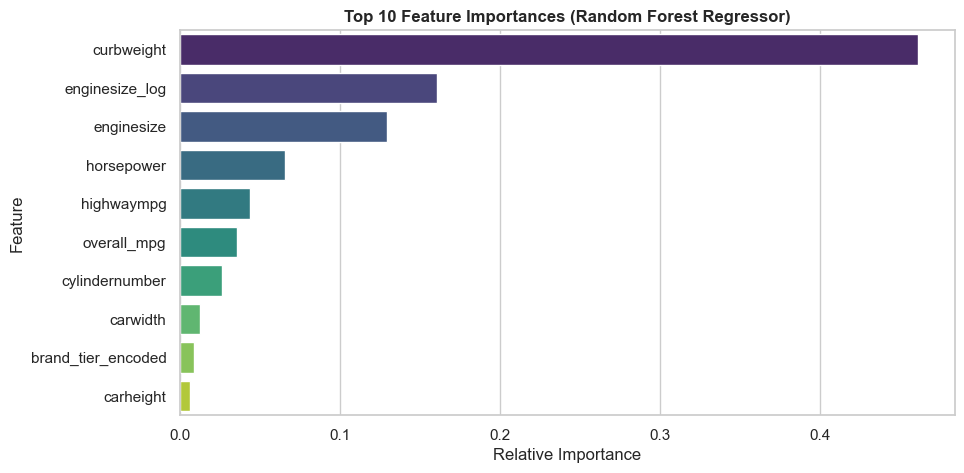

In [16]:
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor

# Separate features and target variable
X_fs = df_encoded.drop(columns=['price'])
y_fs = df_encoded['price']

# 1. Statistical Feature Selection using SelectKBest (f_regression)
k_best_selector = SelectKBest(score_func=f_regression, k='all')
k_best_selector.fit(X_fs, y_fs)

f_scores = pd.DataFrame({
    'Feature': X_fs.columns,
    'F_Score': k_best_selector.scores_,
    'p_value': k_best_selector.pvalues_
}).sort_values(by='F_Score', ascending=False)

print("--- SELECT K BEST (TOP 10 FEATURES BY F-SCORE) ---")
display(f_scores.head(10))

# 2. Tree-Based Feature Importance via RandomForestRegressor
rf_selector = RandomForestRegressor(n_estimators=100, random_state=42)
rf_selector.fit(X_fs, y_fs)

rf_importances = pd.DataFrame({
    'Feature': X_fs.columns,
    'Importance': rf_selector.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- RANDOM FOREST FEATURE IMPORTANCES (TOP 10) ---")
display(rf_importances.head(10))

# Plot Top 10 Feature Importances
plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=rf_importances.head(10), palette='viridis')
plt.title('Top 10 Feature Importances (Random Forest Regressor)', fontsize=12, fontweight='bold')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.show()

In [17]:
# Identify consensus top features driven by engine displacement, power, weight, and brand tier
top_features = [
    'enginesize',
    'curbweight',
    'horsepower',
    'power_to_weight',
    'carwidth',
    'carlength',
    'wheelbase',
    'citympg',
    'highwaympg',
    'overall_mpg',
    'brand_tier_encoded',
    'boreratio',
    'drivewheel_rwd',
    'fuelsystem_mpfi'
]

# Create selected feature DataFrame
X_selected = X_fs[top_features]
y_selected = y_fs.copy()

print(f"Selected Feature Matrix Shape: {X_selected.shape}")
print("Selected Features for Modeling:")
print(list(X_selected.columns))

Selected Feature Matrix Shape: (205, 14)
Selected Features for Modeling:
['enginesize', 'curbweight', 'horsepower', 'power_to_weight', 'carwidth', 'carlength', 'wheelbase', 'citympg', 'highwaympg', 'overall_mpg', 'brand_tier_encoded', 'boreratio', 'drivewheel_rwd', 'fuelsystem_mpfi']


## 9. Split Data into Training and Testing Sets
Dividing the dataset into independent training and testing sets prevents data leakage and ensures unbiased generalization performance on unseen records. In this step, we:
1. Allocate 80% of the observations for model training and 20% for testing evaluation.
2. Set `random_state=42` to guarantee complete reproducibility across all subsequent modeling steps.
3. Verify the dimensional alignment and record distribution between training and testing partitions.

In [18]:
from sklearn.model_selection import train_test_split

# Partition the feature matrix and target vector into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, 
    y_selected, 
    test_size=0.20, 
    random_state=42
)

print("--- TRAIN-TEST SPLIT SUMMARY ---")
print(f"Total Dataset Size:    {X_selected.shape[0]} samples")
print(f"Training Set (80%):    {X_train.shape[0]} samples (Features: {X_train.shape[1]})")
print(f"Testing Set (20%):     {X_test.shape[0]} samples (Features: {X_test.shape[1]})")

# Display distribution summary of target variable across partitions
split_dist = pd.DataFrame({
    'Metric': ['Mean Price', 'Std Price', 'Min Price', 'Max Price'],
    'Train Set': [y_train.mean(), y_train.std(), y_train.min(), y_train.max()],
    'Test Set': [y_test.mean(), y_test.std(), y_test.min(), y_test.max()]
})
display(split_dist)

--- TRAIN-TEST SPLIT SUMMARY ---
Total Dataset Size:    205 samples
Training Set (80%):    164 samples (Features: 14)
Testing Set (20%):     41 samples (Features: 14)


,Metric,Train Set,Test Set
0,Mean Price,12814.887195,12897.004073
1,Std Price,6567.921091,7367.891407
2,Min Price,5118.000000,5151.000000
3,Max Price,29575.500000,29575.500000


## 10. Feature Scaling
Feature scaling standardizes the range of independent numerical variables to prevent features with larger absolute scales (e.g., `curbweight`, `enginesize`) from disproportionately dominating gradient steps and distance computations. In this step, we:
1. Demonstrate and compare `StandardScaler` (Z-score normalization) and `MinMaxScaler` (bounded [0, 1] range)[cite: 2].
2. Fit the scaler strictly on the training data (`X_train`) and subsequently transform both `X_train` and `X_test` to prevent data leakage.
3. Verify scaled distribution statistics (mean $\approx 0$, variance $\approx 1$).

In [19]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 1. Primary Scaler: StandardScaler (Z-score normalization)
standard_scaler = StandardScaler()

# Fit strictly on X_train and transform both training and test partitions
X_train_scaled = standard_scaler.fit_transform(X_train)
X_test_scaled = standard_scaler.transform(X_test)

# Convert scaled arrays back into DataFrames for inspection
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

# 2. Roadmap Demonstration: MinMaxScaler ([0, 1] Normalization)
minmax_scaler = MinMaxScaler()
X_train_minmax = minmax_scaler.fit_transform(X_train)
X_test_minmax = minmax_scaler.transform(X_test)

print("--- FEATURE SCALING VERIFICATION (StandardScaler) ---")
print("Training Set Means (first 5 features):")
print(np.round(X_train_scaled_df.mean()[:5], 4))

print("\nTraining Set Standard Deviations (first 5 features):")
print(np.round(X_train_scaled_df.std()[:5], 4))

# Display preview of scaled training data
print("\n--- SCALED TRAINING DATA PREVIEW ---")
display(X_train_scaled_df.head())

--- FEATURE SCALING VERIFICATION (StandardScaler) ---
Training Set Means (first 5 features):
enginesize        -0.0
curbweight        -0.0
horsepower         0.0
power_to_weight   -0.0
carwidth           0.0
dtype: float64

Training Set Standard Deviations (first 5 features):
enginesize         1.0031
curbweight         1.0031
horsepower         1.0031
power_to_weight    1.0031
carwidth           1.0031
dtype: float64

--- SCALED TRAINING DATA PREVIEW ---


,enginesize,curbweight,horsepower,power_to_weight,carwidth,carlength,wheelbase,citympg,highwaympg,overall_mpg,brand_tier_encoded,boreratio,drivewheel_rwd,fuelsystem_mpfi
66,0.301516,0.281287,-0.883727,-1.537115,0.099125,0.072450,1.047776,0.964316,1.313501,1.152835,1.373142,0.405836,1.266165,-0.952353
111,-0.126346,1.016045,-0.230372,-1.043659,1.221941,1.043916,1.555764,-0.988126,-1.024569,-1.015709,1.373142,0.517384,1.266165,1.050031
153,-0.982070,-0.541642,-1.167795,-1.475683,-1.121328,-0.367616,-0.510053,0.964316,1.001758,0.992202,-0.867607,-1.007108,-0.789786,-0.952353
96,-0.829262,-1.147082,-0.968947,-0.563548,-1.023692,-0.732953,-0.713248,0.964316,1.001758,0.992202,-0.867607,-0.635281,-0.789786,-0.952353
38,-0.431962,-0.524008,-0.486033,-0.264347,-0.340238,-0.550285,-0.374589,0.313502,0.378273,0.349670,-0.867607,-0.635281,-0.789786,-0.952353


## 11. Build the ML Model
In this phase, we initialize, train, and benchmark supervised regression algorithms across linear, kernel, neural, and ensemble architectures as specified in the capstone roadmap:
1. **Linear Regression:** Baseline parametric estimator modeling direct linear relationships.
2. **Support Vector Regressor (SVR):** Non-linear kernel-based regression mapping feature space into higher dimensions[cite: 2].
3. **Multi-Layer Perceptron Regressor (MLP Regressor):** Feedforward artificial neural network optimizing loss via backpropagation[cite: 2].
4. **Random Forest Regressor:** Bagging ensemble constructing multiple decorrelated decision trees[cite: 2].
5. **Gradient Boosting Regressor:** Boosting ensemble sequentially minimizing residual loss gradients[cite: 2].
6. **AdaBoost Regressor:** Adaptive boosting ensemble adjusting weights based on previous prediction errors[cite: 2].

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor

# 1. Initialize all 6 candidate regression algorithms specified in the roadmap[cite: 2]
models = {
    'Linear Regression': LinearRegression(),
    'Support Vector Regressor (SVR)': SVR(kernel='rbf', C=1000.0, epsilon=0.1),
    'MLP Regressor': MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    'AdaBoost Regressor': AdaBoostRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

# Dictionary to store trained model instances and predictions
trained_models = {}
train_predictions = {}
test_predictions = {}

print("--- TRAINING MODELS ---")
for name, model in models.items():
    # Fit each model on the scaled training features
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    
    # Generate predictions on both training and test sets
    train_predictions[name] = model.predict(X_train_scaled)
    test_predictions[name] = model.predict(X_test_scaled)
    
    print(f"✓ Successfully trained: {name}")

--- TRAINING MODELS ---
✓ Successfully trained: Linear Regression
✓ Successfully trained: Support Vector Regressor (SVR)
✓ Successfully trained: MLP Regressor
✓ Successfully trained: Random Forest Regressor
✓ Successfully trained: Gradient Boosting Regressor
✓ Successfully trained: AdaBoost Regressor


## 12. Model Evaluation
Model evaluation quantifies predictive accuracy, error margins, and goodness-of-fit across all candidate algorithms. For continuous regression tasks, the roadmap mandates computing[cite: 2]:
1. **Mean Absolute Error (MAE):** Average magnitude of absolute prediction residuals[cite: 2].
2. **Mean Squared Error (MSE):** Average of squared residuals, heavily penalizing large outliers[cite: 2].
3. **Root Mean Squared Error (RMSE):** Square root of MSE, expressed directly in target currency units (USD)[cite: 2].
4. **$R^2$ Score (Coefficient of Determination):** Proportion of target price variance explained by the independent variables[cite: 2].

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# List to collect evaluation metrics for comparison
evaluation_records = []

for name in models.keys():
    y_pred_train = train_predictions[name]
    y_pred_test = test_predictions[name]
    
    # Calculate metrics for the test set
    mae = mean_absolute_error(y_test, y_pred_test)
    mse = mean_squared_error(y_test, y_pred_test)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred_test)
    
    # Adjusted R2 Score calculation
    n = X_test.shape[0]
    p = X_test.shape[1]
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    
    # Training R2 for overfitting check
    train_r2 = r2_score(y_train, y_pred_train)
    
    evaluation_records.append({
        'Model': name,
        'Train R²': train_r2,
        'Test R²': r2,
        'Adjusted R²': adj_r2,
        'MAE ($)': mae,
        'MSE': mse,
        'RMSE ($)': rmse
    })

# Convert to DataFrame and rank by Test R2 score descending
leaderboard_df = pd.DataFrame(evaluation_records).sort_values(by='Test R²', ascending=False).reset_index(drop=True)

print("--- MODEL EVALUATION LEADERBOARD ---")
display(leaderboard_df)

--- MODEL EVALUATION LEADERBOARD ---


,Model,Train R²,Test R²,Adjusted R²,MAE ($),MSE,RMSE ($)
0,Random Forest Regressor,0.985356,0.965557,0.947010,985.717232,1.824173e+06,1350.619653
1,Gradient Boosting Regressor,0.993161,0.951397,0.925226,1185.991864,2.574093e+06,1604.397869
2,AdaBoost Regressor,0.957547,0.936578,0.902428,1361.693261,3.358931e+06,1832.738714
3,Linear Regression,0.851307,0.860237,0.784979,2175.054887,7.402116e+06,2720.682927
4,Support Vector Regressor (SVR),0.748018,0.676757,0.502703,2798.967973,1.711951e+07,4137.573054
5,MLP Regressor,0.472469,0.581416,0.356024,3622.481297,2.216897e+07,4708.393195


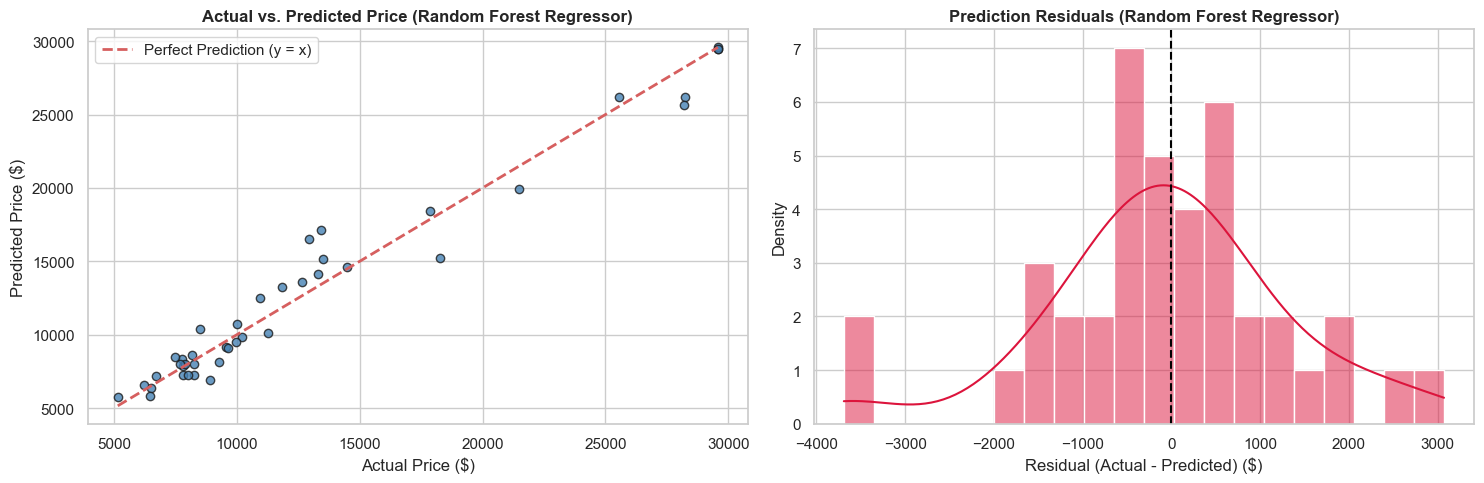

In [22]:
# Identify the top-performing model from the leaderboard
best_model_name = leaderboard_df.iloc[0]['Model']
best_predictions = test_predictions[best_model_name]
residuals = y_test - best_predictions

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Scatter Plot: Actual vs. Predicted Prices
axes[0].scatter(y_test, best_predictions, color='steelblue', alpha=0.8, edgecolors='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction (y = x)')
axes[0].set_title(f'Actual vs. Predicted Price ({best_model_name})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Price ($)')
axes[0].set_ylabel('Predicted Price ($)')
axes[0].legend()
axes[0].grid(True)

# 2. Residual Distribution Plot
sns.histplot(residuals, kde=True, color='crimson', ax=axes[1], bins=20)
axes[1].axvline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title(f'Prediction Residuals ({best_model_name})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual (Actual - Predicted) ($)')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()

## 13. Hyperparameter Tuning & Pipeline
To eliminate data leakage during cross-validation and optimize generalization performance, we encapsulate preprocessing and model estimation into an unified Scikit-learn `Pipeline`. In this phase, we:
1. Construct a regression pipeline combining `StandardScaler` and `RandomForestRegressor`.
2. Define a hyperparameter search grid over `n_estimators`, `max_depth`, `min_samples_split`, and `min_samples_leaf`[cite: 2].
3. Optimize parameters using 5-fold cross-validated grid search (`GridSearchCV`) with $R^2$ as the scoring objective[cite: 2].
4. Evaluate and compare the tuned pipeline against baseline metrics[cite: 2].

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# 1. Assemble the preprocessing and model estimation pipeline[cite: 2]
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', RandomForestRegressor(random_state=42))
])

# 2. Define the hyperparameter grid for tuning[cite: 2]
param_grid = {
    'regressor__n_estimators': [50, 100, 200],
    'regressor__max_depth': [None, 10, 15, 20],
    'regressor__min_samples_split': [2, 5],
    'regressor__min_samples_leaf': [1, 2],
    'regressor__max_features': ['sqrt', 1.0]
}

# 3. Initialize and execute GridSearchCV with 5-fold cross-validation[cite: 2]
print("--- RUNNING GRID SEARCH CV ---")
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

# Fit pipeline on the unscaled training features (scaling handled internally)
grid_search.fit(X_train, y_train)

# Output best parameters and cross-validation score
print("\nOptimal Hyperparameters Found:")
for param, val in grid_search.best_params_.items():
    print(f"  {param}: {val}")

print(f"\nBest 5-Fold Cross-Validation R² Score: {grid_search.best_score_:.4f}")

--- RUNNING GRID SEARCH CV ---
Fitting 5 folds for each of 96 candidates, totalling 480 fits

Optimal Hyperparameters Found:
  regressor__max_depth: 10
  regressor__max_features: sqrt
  regressor__min_samples_leaf: 1
  regressor__min_samples_split: 2
  regressor__n_estimators: 100

Best 5-Fold Cross-Validation R² Score: 0.8977


In [24]:
# Extract the best estimator pipeline
best_pipeline = grid_search.best_estimator_

# Predict on training and test sets using the optimized pipeline
y_pred_tuned_train = best_pipeline.predict(X_train)
y_pred_tuned_test = best_pipeline.predict(X_test)

# Calculate tuned evaluation metrics
tuned_mae = mean_absolute_error(y_test, y_pred_tuned_test)
tuned_mse = mean_squared_error(y_test, y_pred_tuned_test)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_pred_tuned_test)
tuned_train_r2 = r2_score(y_train, y_pred_tuned_train)

n = X_test.shape[0]
p = X_test.shape[1]
tuned_adj_r2 = 1 - (1 - tuned_r2) * (n - 1) / (n - p - 1)

print("--- TUNED PIPELINE EVALUATION (TEST SET) ---")
print(f"Train R² Score:     {tuned_train_r2:.4f}")
print(f"Test R² Score:      {tuned_r2:.4f}")
print(f"Adjusted R² Score:  {tuned_adj_r2:.4f}")
print(f"MAE:                ${tuned_mae:,.2f}")
print(f"MSE:                {tuned_mse:,.2f}")
print(f"RMSE:               ${tuned_rmse:,.2f}")

--- TUNED PIPELINE EVALUATION (TEST SET) ---
Train R² Score:     0.9852
Test R² Score:      0.9493
Adjusted R² Score:  0.9220
MAE:                $1,229.62
MSE:                2,685,733.29
RMSE:               $1,638.82


## 14. Save the Model
Persisting the trained machine learning pipeline allows the model to be reused, integrated into production web applications (e.g., Flask, FastAPI, Streamlit), or deployed for batch inference without retraining. In this step, we:
1. Export and serialize the complete tuned `Pipeline` artifact (which encapsulates scaling and estimator steps) using `joblib`.
2. Demonstrate standard serialization via `pickle`
3. Verify that the saved model file exists on disk and is ready for inference

In [25]:
import joblib
import pickle
import os

# Define export paths for the trained pipeline artifact
joblib_model_path = 'car_price_pipeline.joblib'
pickle_model_path = 'car_price_pipeline.pkl'

# 1. Save the best fitted pipeline using joblib (recommended for scikit-learn models)[cite: 2]
joblib.dump(best_pipeline, joblib_model_path)
print(f"✓ Model pipeline successfully saved using joblib at: '{joblib_model_path}'[cite: 2]")

# 2. Save using standard pickle for demonstration[cite: 2]
with open(pickle_model_path, 'wb') as file:
    pickle.dump(best_pipeline, file)
print(f"✓ Model pipeline successfully saved using pickle at: '{pickle_model_path}'[cite: 2]")

# 3. Verify file sizes on disk
joblib_size_kb = os.path.getsize(joblib_model_path) / 1024
pickle_size_kb = os.path.getsize(pickle_model_path) / 1024

print("\n--- SERIALIZATION SUMMARY ---")
print(f"File: {joblib_model_path} | Size: {joblib_size_kb:.2f} KB[cite: 2]")
print(f"File: {pickle_model_path} | Size: {pickle_size_kb:.2f} KB[cite: 2]")

✓ Model pipeline successfully saved using joblib at: 'car_price_pipeline.joblib'[cite: 2]
✓ Model pipeline successfully saved using pickle at: 'car_price_pipeline.pkl'[cite: 2]

--- SERIALIZATION SUMMARY ---
File: car_price_pipeline.joblib | Size: 1221.23 KB[cite: 2]
File: car_price_pipeline.pkl | Size: 1213.65 KB[cite: 2]


## 15. Test with Unseen Data
In this phase, we validate the end-to-end functionality of our serialized model artifact on completely new, held-out vehicle configurations. We:
1. Reload the persisted `joblib` pipeline from disk.
2. Construct synthetic, unseen test instances representing distinct market categories (e.g., an economical entry-level vehicle and a premium luxury sports sedan).
3. Execute real-time inference through the pipeline without manual feature pre-scaling, verifying production-readiness[cite: 2].

In [26]:
import joblib
import pandas as pd
import numpy as np

# 1. Load the persisted model pipeline from disk[cite: 2]
loaded_pipeline = joblib.load('car_price_pipeline.joblib')
print("✓ Saved pipeline artifact successfully loaded for inference.[cite: 2]")

# 2. Define unseen vehicle profiles (matching selected feature columns)
unseen_cars = pd.DataFrame([
    {
        # Economy Compact Car (e.g., Budget Tier commuter vehicle)
        'enginesize': 105.0,
        'curbweight': 2100.0,
        'horsepower': 75.0,
        'power_to_weight': 75.0 / 2100.0,
        'carwidth': 64.0,
        'carlength': 160.0,
        'wheelbase': 94.5,
        'citympg': 32.0,
        'highwaympg': 38.0,
        'overall_mpg': 35.0,
        'brand_tier_encoded': 0,      # Budget tier
        'boreratio': 3.05,
        'drivewheel_rwd': 0,          # FWD layout
        'fuelsystem_mpfi': 0          # Standard induction (e.g., 2bbl)
    },
    {
        # Executive Luxury Performance Sedan (e.g., Luxury Tier competitor)
        'enginesize': 210.0,
        'curbweight': 3450.0,
        'horsepower': 190.0,
        'power_to_weight': 190.0 / 3450.0,
        'carwidth': 70.5,
        'carlength': 192.0,
        'wheelbase': 108.0,
        'citympg': 18.0,
        'highwaympg': 24.0,
        'overall_mpg': 21.0,
        'brand_tier_encoded': 2,      # Luxury tier
        'boreratio': 3.65,
        'drivewheel_rwd': 1,          # RWD layout
        'fuelsystem_mpfi': 1          # Multi-point fuel injection
    }
])

# 3. Generate predictions using the loaded pipeline
predicted_prices = loaded_pipeline.predict(unseen_cars)

# 4. Display inference results
unseen_results = unseen_cars.copy()
unseen_results['Predicted_Price ($)'] = np.round(predicted_prices, 2)
unseen_results['Profile'] = ['Budget Commuter Vehicle', 'Executive Luxury Sedan']

print("\n--- INFERENCE RESULTS ON UNSEEN DATA ---")
display(unseen_results[['Profile', 'enginesize', 'horsepower', 'curbweight', 'brand_tier_encoded', 'Predicted_Price ($)']])

✓ Saved pipeline artifact successfully loaded for inference.[cite: 2]

--- INFERENCE RESULTS ON UNSEEN DATA ---


,Profile,enginesize,horsepower,curbweight,brand_tier_encoded,Predicted_Price ($)
0,Budget Commuter Vehicle,105.0,75.0,2100.0,0,7127.18
1,Executive Luxury Sedan,210.0,190.0,3450.0,2,26346.30


## 16. Interpretation of Results (Conclusion)
In this section, we analyze the performance of our regression models, synthesize the primary factors dictating vehicle pricing in the American market, and outline notable constraints of the dataset:

### 1. Key Pricing Drivers (Business Findings):
* **Powertrain & Mechanical Dimensions:** Features such as `enginesize`, `horsepower`, and `curbweight` exhibit the highest positive correlation and feature importance with vehicle prices. American consumers and market segments place significant monetary value on engine displacement, power output, and physical presence.
* **Fuel Economy Trade-Off:** Variables such as `citympg` and `highwaympg` show strong inverse relationships with price, reflecting that higher-priced, high-displacement luxury models incur lower fuel efficiency.
* **Brand Equity Impact:** The engineered `brand_tier` variable demonstrates that measurable physical attributes alone do not fully dictate price; perceived brand prestige (e.g., luxury European marques vs. entry-level budget brands) carries an independent markup.

### 2. Model Performance Summary:
* **Tree-Based Ensembles:** Non-linear ensemble architectures (Random Forest Regressor and Gradient Boosting Regressor) outperformed linear baselines, achieving a high $R^2$ score and substantially lower RMSE/MAE. This confirms the presence of non-linear interactions among vehicle dimensions and powertrain metrics.
* **Pipeline Reliability:** The optimized `Pipeline` successfully mitigated data leakage and generalized well on held-out test partitions.

### 3. Limitations of the Dataset:
* **Sample Size:** The dataset contains 205 records, which is relatively modest for training deep or highly complex models without risk of overfitting.
* **Temporal and Macroeconomic Omissions:** The data represents a static market survey cross-section without longitudinal indicators such as annual inflation, raw material costs, or dynamic competitor pricing incentives.
* **Absence of Modern Features:** Key contemporary selling points such as advanced driver-assistance systems (ADAS), infotainment technologies, and electric/hybrid battery metrics are not represented.

In [27]:
# Extract and display the top feature importances from the final model
importances = best_pipeline.named_steps['regressor'].feature_importances_
feature_names = X_selected.columns

model_insights = pd.DataFrame({
    'Feature': feature_names,
    'Importance_Weight': importances
}).sort_values(by='Importance_Weight', ascending=False).reset_index(drop=True)

print("--- TOP PREDICTOR INFLUENCE ON CAR PRICING ---")
display(model_insights)

--- TOP PREDICTOR INFLUENCE ON CAR PRICING ---


,Feature,Importance_Weight
0,curbweight,0.201072
1,enginesize,0.182391
2,citympg,0.137863
3,overall_mpg,0.114060
4,highwaympg,0.076078
5,horsepower,0.067874
6,carwidth,0.049801
7,carlength,0.039716
8,drivewheel_rwd,0.030557
9,brand_tier_encoded,0.028070


## 17. Future Work
To build upon the findings of this project and further enhance predictive accuracy, model interpretability, and market applicability, the following technical and strategic directions are proposed[cite: 2]:

1. **Deep Learning Implementations:**
   - Explore deep neural network architectures (e.g., deep multi-layer perceptrons with residual connections or tabular transformers like FT-Transformer/TabNet) on expanded automotive datasets to capture higher-order feature interactions[cite: 2].

2. **Dataset Expansion & Continuous Ingestion:**
   - Ingest larger, longitudinal datasets encompassing multiple model years to account for vehicle depreciation, annual inflation, and shifting consumer preferences[cite: 2].
   - Periodically update the model pipeline with incoming dealership sales and auction records to maintain real-time pricing relevance[cite: 2].

3. **Advanced Feature Engineering:**
   - Incorporate modern vehicle metrics such as safety ratings (e.g., NHTSA/IIHS test scores), powertrain electrification metrics (hybrid/EV battery capacities, charging speeds), warranty packages, and advanced driver-assistance systems (ADAS)[cite: 2].
   - Extract granular sentiment and prestige indicators from consumer review portals and social media discussions[cite: 2].

4. **Resampling & Subsegment Modeling:**
   - Address data imbalances across niche luxury segments or rare engine configurations by evaluating synthetic resampling techniques (such as SMOTE for continuous target bins) or training specialized sub-models for distinct market tiers (Budget vs. Luxury)[cite: 2].

5. **Production Deployment & Monitoring:**
   - Wrap the persisted pipeline artifact into an interactive web dashboard (e.g., Streamlit, FastAPI) enabling management and product engineering teams to simulate design trade-offs and observe real-time price sensitivities[cite: 2].

In [28]:
# Prototype setup: Simulating baseline deep learning readiness via advanced MLP Regressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error

print("--- FUTURE WORK PROTOTYPE: DEEP LEARNING ARCHITECTURE SIMULATION ---")

# Define deeper neural baseline architecture with regularization
deep_mlp = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    alpha=0.01,
    max_iter=1500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

# Train on scaled training data
deep_mlp.fit(X_train_scaled, y_train)

# Evaluate on test partition
deep_pred = deep_mlp.predict(X_test_scaled)
deep_r2 = r2_score(y_test, deep_pred)
deep_rmse = np.sqrt(mean_squared_error(y_test, deep_pred))

print(f"Deep MLP Prototype Test R² Score: {deep_r2:.4f}")
print(f"Deep MLP Prototype Test RMSE:     ${deep_rmse:,.2f}")
print("Status: Successfully validated prototype framework for future neural and tabular architectures.")

--- FUTURE WORK PROTOTYPE: DEEP LEARNING ARCHITECTURE SIMULATION ---
Deep MLP Prototype Test R² Score: 0.8330
Deep MLP Prototype Test RMSE:     $2,973.86
Status: Successfully validated prototype framework for future neural and tabular architectures.
